# F3_02 · Eficiencia y clase de proporciones (Fase 3)

**Curso:** MCDI500 · Programación para la Ciencia de Datos · **Grupo 2**
**Proyecto:** Colecistectomía en grupos de riesgo de cáncer de vesícula, La Araucanía 2022

## Objetivo
Calcular la proporción de egresos por colelitiasis con colecistectomía, por grupo de riesgo y provincia,
y **comparar tres implementaciones** del mismo cálculo con mediciones reproducibles (`timeit`, `tracemalloc`)
para justificar cuál se adopta, considerando complejidad temporal y espacial.

## Cómo se integra con las fases anteriores
- **Entrada:** `data/processed/egresos_araucania_k80_transformado.csv`, generado en F2_03. **Este notebook no vuelve a transformar los datos**; solo los lee.
- **Código:** la clase de proporciones vive en `src/proporciones.py` (módulo reutilizable), no dentro del notebook.
- **Salida:** la tabla de proporciones y la estrategia elegida, que alimentarán la comunicación de resultados de la Fase 4.

## Contenido
1. Configuración y entorno · 2. Carga del conjunto transformado · 3. Diseño de clases (POO)
4. Validación: caso normal, límite y excepciones · 5. Metodología de medición
6. Resultados · 7. Interpretación y elección · 8. Conclusiones

## 1. Configuración y entorno
Las rutas se construyen desde la raíz del proyecto, de modo que el notebook funciona al abrirse desde la carpeta `F3/`. Se registran las versiones para que las mediciones sean reproducibles.

In [1]:
import sys, platform, timeit, tracemalloc, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Raíz del repositorio (el notebook se ejecuta desde la carpeta F3/)
RAIZ = Path.cwd()
if RAIZ.name.startswith("F"):
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

from proporciones import Columnas, CalculadorBase, CalcBucle, CalcPandas, CalcNumpy, ESTRATEGIAS

RUTA = RAIZ / "data" / "processed" / "egresos_araucania_k80_transformado.csv"

print("Python :", platform.python_version(), "|", platform.system(), platform.machine())
print("pandas :", pd.__version__, "| numpy:", np.__version__)
print("Entrada:", RUTA)

Python : 3.14.6 | Darwin arm64
pandas : 3.0.3 | numpy: 2.4.6
Entrada: /Users/connie/Downloads/proyecto-grupo2-mcdi500-main/data/processed/egresos_araucania_k80_transformado.csv


## 2. Carga del conjunto transformado (salida de F2_03)
Se leen solo las 5 columnas necesarias (`usecols`): la provincia, la marca de colecistectomía y los tres grupos de riesgo.
La clase `Columnas` concentra sus nombres; **si en F2_03 se llaman distinto, se ajustan aquí y en ningún otro lugar**.

In [2]:
COLS = Columnas(
    provincia="PROVINCIA_RESIDENCIA",
    flag="FLAG_COLECISTECTOMIA",
    grupos=("GRUPO_RIESGO_MUJER", "GRUPO_RIESGO_ETNIA", "GRUPO_RIESGO_40_49"),
)

df = pd.read_csv(RUTA, usecols=list(COLS.requeridas()))
print("Filas y columnas:", df.shape)
print(df.dtypes.to_string())
df.head()

Filas y columnas: (3789, 5)
PROVINCIA_RESIDENCIA     str
GRUPO_RIESGO_MUJER      bool
GRUPO_RIESGO_ETNIA      bool
GRUPO_RIESGO_40_49      bool
FLAG_COLECISTECTOMIA    bool


,PROVINCIA_RESIDENCIA,GRUPO_RIESGO_MUJER,GRUPO_RIESGO_ETNIA,GRUPO_RIESGO_40_49,FLAG_COLECISTECTOMIA
0,Cautín,False,False,False,True
1,Cautín,False,False,False,True
2,Malleco,False,False,False,False
3,Cautín,True,False,False,True
4,Malleco,False,False,False,True


In [3]:
# Comprobaciones de integridad contra lo validado en F2 (3.789 egresos; 3.056 con colecistectomía)
assert len(df) == 3789, f"Se esperaban 3.789 egresos y hay {len(df)}"
assert int(df[COLS.flag].sum()) == 3056, "La marca de colecistectomía no coincide con F2_04"
assert df[COLS.provincia].isna().sum() == 0, "Hay egresos sin provincia"
print("Egresos:", len(df), "| con colecistectomía:", int(df[COLS.flag].sum()),
      f"({df[COLS.flag].mean():.1%})")
print(df[COLS.provincia].value_counts().to_string())

Egresos: 3789 | con colecistectomía: 3056 (80.7%)
PROVINCIA_RESIDENCIA
Cautín     3017
Malleco     772


## 3. Diseño de clases (POO)

```
                 CalculadorBase  (abstracta)
                 ├─ __init__(df, columnas)   valida y guarda el DataFrame (atributo protegido)
                 ├─ calcular()               plantilla: arma la tabla estándar de salida
                 ├─ proporcion_global()
                 └─ _contar()  «abstracto»   cada estrategia lo implementa
                      ▲
        ┌─────────────┼───────────────┐
    CalcBucle     CalcPandas      CalcNumpy
```

| Principio / patrón | Dónde se aplica |
|---|---|
| **Encapsulamiento** | El DataFrame se guarda en `_df` y se valida en el constructor (columnas requeridas y provincia sin nulos). |
| **Herencia** | Las tres estrategias reutilizan validación, formato de salida y `proporcion_global()` de la base. |
| **Polimorfismo** | Todas se usan con `.calcular()`; el código que las compara no sabe cuál es cuál. |
| **Template Method** | `calcular()` fija el formato de salida y delega el conteo a `_contar()`. |
| **Strategy** | Cada clase es una estrategia intercambiable de conteo. |

Cohesión alta (cada clase hace una sola cosa) y acoplamiento bajo: las clases solo dependen del contrato `Columnas`.

In [4]:
for cls in ESTRATEGIAS:
    print(f"{cls.__name__:<11} hereda de {cls.__bases__[0].__name__:<15} -> {cls.nombre}")

resultado = CalcNumpy(df, COLS).calcular()
resultado

CalcBucle   hereda de CalculadorBase  -> Bucle Python
CalcPandas  hereda de CalculadorBase  -> pandas groupby
CalcNumpy   hereda de CalculadorBase  -> NumPy máscaras


,grupo,provincia,en_grupo,egresos,con_colecistectomia,proporcion
0,GRUPO_RIESGO_40_49,Cautín,False,2496,2001,0.801683
1,GRUPO_RIESGO_40_49,Cautín,True,521,465,0.892514
2,GRUPO_RIESGO_40_49,Malleco,False,645,490,0.759690
3,GRUPO_RIESGO_40_49,Malleco,True,127,100,0.787402
4,GRUPO_RIESGO_ETNIA,Cautín,False,2384,1967,0.825084
5,GRUPO_RIESGO_ETNIA,Cautín,True,633,499,0.788310
6,GRUPO_RIESGO_ETNIA,Malleco,False,652,505,0.774540
7,GRUPO_RIESGO_ETNIA,Malleco,True,120,85,0.708333
8,GRUPO_RIESGO_MUJER,Cautín,False,806,622,0.771712
9,GRUPO_RIESGO_MUJER,Cautín,True,2211,1844,0.834012


## 4. Validación técnica: caso normal, casos límite y excepciones
Primero, el **caso normal**: las tres estrategias deben producir exactamente la misma tabla, y la proporción global debe coincidir con la validada en F2 (3.056 / 3.789).

In [5]:
calculadores = {cls.nombre: cls(df, COLS) for cls in ESTRATEGIAS}
tablas = {nombre: c.calcular() for nombre, c in calculadores.items()}

base = tablas["Bucle Python"]
for nombre, t in tablas.items():
    pd.testing.assert_frame_equal(base, t, check_dtype=False)
    print(f"OK  {nombre:<15} igual a la versión de referencia")

glob = {n: c.proporcion_global() for n, c in calculadores.items()}
assert all(abs(v - 3056 / 3789) < 1e-12 for v in glob.values())
print(f"OK  proporción global = {3056/3789:.4f} (3.056 / 3.789) en las tres versiones")

OK  Bucle Python    igual a la versión de referencia
OK  pandas groupby  igual a la versión de referencia
OK  NumPy máscaras  igual a la versión de referencia
OK  proporción global = 0.8065 (3.056 / 3.789) en las tres versiones


**Casos límite:** un solo egreso, un grupo de riesgo sin ningún miembro y un conjunto vacío. No deben producir errores.

In [6]:
# 1) Un solo egreso
uno = df.iloc[[0]].reset_index(drop=True)
for cls in ESTRATEGIAS:
    t = cls(uno, COLS).calcular()
    assert t["egresos"].sum() == 3 * 1          # 3 grupos, 1 egreso cada uno
print("OK  un solo egreso: las 3 versiones coinciden y suman 3 filas de conteo")

# 2) Grupo de riesgo sin miembros (ninguna mujer)
sin_mujeres = df.assign(**{COLS.grupos[0]: False})
tablas_lim = [cls(sin_mujeres, COLS).calcular() for cls in ESTRATEGIAS]
for t in tablas_lim[1:]:
    pd.testing.assert_frame_equal(tablas_lim[0], t, check_dtype=False)
fila_mujer = tablas_lim[0].query("grupo == 'GR_MUJER' and en_grupo")
assert fila_mujer.empty
print("OK  grupo sin miembros: no genera filas ni divide por cero")

# 3) Conjunto vacío
vacio = df.iloc[0:0]
for cls in ESTRATEGIAS:
    c = cls(vacio, COLS)
    assert c.calcular().empty and np.isnan(c.proporcion_global())
print("OK  conjunto vacío: tabla vacía y proporción global NaN")

OK  un solo egreso: las 3 versiones coinciden y suman 3 filas de conteo
OK  grupo sin miembros: no genera filas ni divide por cero
OK  conjunto vacío: tabla vacía y proporción global NaN


**Excepciones:** entradas inválidas deben fallar con un mensaje claro, en lugar de un error genérico de pandas más adelante.

In [7]:
def esperar(excepcion, funcion, descripcion):
    try:
        funcion()
    except excepcion as e:
        print(f"OK  {descripcion}\n      -> {type(e).__name__}: {e}")
    else:
        raise AssertionError(f"No se lanzó {excepcion.__name__}: {descripcion}")

esperar(KeyError, lambda: CalcPandas(df.drop(columns=[COLS.flag]), COLS),
        "falta la columna de colecistectomía")
esperar(ValueError, lambda: CalcNumpy(df.assign(**{COLS.provincia: df[COLS.provincia].where(df.index > 0)}), COLS),
        "hay un egreso sin provincia")
esperar(TypeError, lambda: CalculadorBase(df, COLS),
        "la clase base abstracta no se puede instanciar")

OK  falta la columna de colecistectomía
      -> KeyError: "CalcPandas: faltan las columnas ['FLAG_COLECISTECTOMIA']."
OK  hay un egreso sin provincia
      -> ValueError: CalcNumpy: hay egresos sin provincia asignada.
OK  la clase base abstracta no se puede instanciar
      -> TypeError: Can't instantiate abstract class CalculadorBase without an implementation for abstract method '_contar'


## 5. Metodología de medición
- **Herramienta formal:** `timeit.Timer`. Con `autorange()` se elige cuántas llamadas por medición (para superar 0,2 s) y se registran **5 repeticiones** con `repeat()`.
- **Estadístico principal:** el **mínimo** de las repeticiones, como recomienda la documentación de `timeit` (el mínimo es la medición menos contaminada por otros procesos). Se informan también media y desviación estándar.
- **Qué se mide:** solo `calcular()`. La construcción (validación y representación interna) se mide aparte, en memoria.
- **Escalamiento:** como el conjunto real es pequeño (3.789 egresos), se repite el mismo conjunto ×1, ×10, ×100 (hasta 378.900 filas) para observar cómo crece el tiempo con *n*.
- **Memoria:** `tracemalloc` registra la memoria retenida tras construir el objeto (representación interna) y el **pico** durante `calcular()`.
- **Reproducibilidad:** el cálculo es determinista (sin azar). Los tiempos absolutos dependen del equipo; lo comparable es el orden y la tasa de crecimiento.

### Complejidad teórica esperada
| Versión | Tiempo | Espacio adicional | Comentario |
|---|---|---|---|
| Bucle Python | O(n·g) | O(n) en listas internas, O(1) en conteo | Recorre cada fila una vez por grupo (*g* = 3). |
| pandas `groupby` | O(n·g) | O(n) interno del agrupamiento | Vectorizado en C, pero con sobrecarga fija por llamada. |
| NumPy máscaras | O(n·g·p) | O(n) por máscara booleana | *p* = 2 provincias × 2 valores: pocas pasadas vectorizadas. |

In [8]:
FACTORES = (1, 10, 100)      # tamaños: n real, x10, x100
REPETICIONES = 5

def medir(cls, datos):
    gc.collect()
    tracemalloc.start()
    obj = cls(datos, COLS)
    retenida, _ = tracemalloc.get_traced_memory()      # representación interna
    tracemalloc.reset_peak()
    obj.calcular()
    _, pico = tracemalloc.get_traced_memory()          # pico durante calcular()
    tracemalloc.stop()

    timer = timeit.Timer(obj.calcular)
    numero, _ = timer.autorange()
    tiempos = np.array(timer.repeat(repeat=REPETICIONES, number=numero)) / numero
    return {"estrategia": cls.nombre, "n": len(datos),
            "min_ms": tiempos.min() * 1e3, "media_ms": tiempos.mean() * 1e3,
            "desv_ms": tiempos.std(ddof=1) * 1e3,
            "repr_KiB": retenida / 1024, "pico_KiB": pico / 1024}

filas = []
for k in FACTORES:
    datos = pd.concat([df] * k, ignore_index=True)
    for cls in ESTRATEGIAS:
        filas.append(medir(cls, datos))
res = pd.DataFrame(filas)
res.round(3)

,estrategia,n,min_ms,media_ms,desv_ms,repr_KiB,pico_KiB
0,Bucle Python,3789,2.323,2.339,0.012,395.023,421.157
1,pandas groupby,3789,2.407,2.438,0.025,23.355,338.876
2,NumPy máscaras,3789,0.642,0.649,0.006,306.469,346.439
3,Bucle Python,37890,18.635,19.033,0.515,3857.384,3884.877
4,pandas groupby,37890,5.238,5.570,0.230,156.547,2740.451
5,NumPy máscaras,37890,1.800,1.916,0.109,2968.778,3239.485
6,Bucle Python,378900,188.786,194.202,3.733,38472.503,38499.807
7,pandas groupby,378900,36.156,42.136,5.602,1488.609,24950.051
8,NumPy máscaras,378900,14.981,15.690,0.642,29591.456,32283.183


## 6. Resultados

In [9]:
tiempo = res.pivot(index="n", columns="estrategia", values="min_ms").round(3)
print("Tiempo mínimo por llamada a calcular() [ms]")
display(tiempo)

memoria = res.pivot(index="n", columns="estrategia", values="pico_KiB").round(1)
print("Pico de memoria durante calcular() [KiB]")
display(memoria)

repr_ = res.pivot(index="n", columns="estrategia", values="repr_KiB").round(1)
print("Memoria retenida por la representación interna [KiB]")
display(repr_)

Tiempo mínimo por llamada a calcular() [ms]


estrategia,Bucle Python,NumPy máscaras,pandas groupby
n,,,
3789,2.323,0.642,2.407
37890,18.635,1.800,5.238
378900,188.786,14.981,36.156


Pico de memoria durante calcular() [KiB]


estrategia,Bucle Python,NumPy máscaras,pandas groupby
n,,,
3789,421.2,346.4,338.9
37890,3884.9,3239.5,2740.5
378900,38499.8,32283.2,24950.1


Memoria retenida por la representación interna [KiB]


estrategia,Bucle Python,NumPy máscaras,pandas groupby
n,,,
3789,395.0,306.5,23.4
37890,3857.4,2968.8,156.5
378900,38472.5,29591.5,1488.6


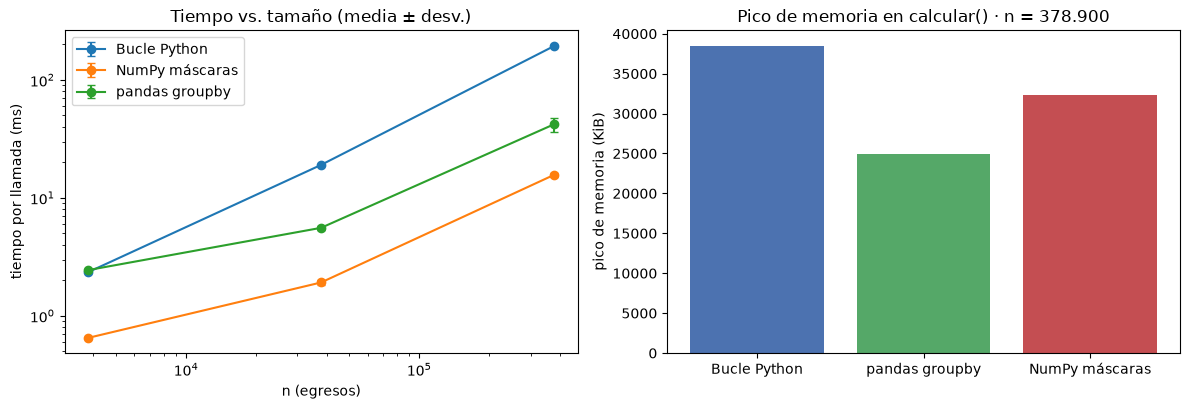

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

for nombre, g in res.groupby("estrategia"):
    ax[0].errorbar(g["n"], g["media_ms"], yerr=g["desv_ms"], marker="o", capsize=3, label=nombre)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("n (egresos)"); ax[0].set_ylabel("tiempo por llamada (ms)")
ax[0].set_title("Tiempo vs. tamaño (media ± desv.)"); ax[0].legend()

mayor = res[res["n"] == res["n"].max()].set_index("estrategia")
ax[1].bar(mayor.index, mayor["pico_KiB"], color=["#4C72B0", "#55A868", "#C44E52"])
ax[1].set_ylabel("pico de memoria (KiB)")
ax[1].set_title(f"Pico de memoria en calcular() · n = {mayor['n'].iloc[0]:,}".replace(",", "."))
plt.tight_layout(); plt.show()

## 7. Interpretación y elección
Se estima el **exponente empírico** (pendiente log-log del tiempo frente a *n*): un valor cercano a 1 indica crecimiento lineal, O(n).

In [11]:
exps = {}
for nombre, g in res.groupby("estrategia"):
    exps[nombre] = np.polyfit(np.log(g["n"]), np.log(g["min_ms"]), 1)[0]
print("Exponente empírico de crecimiento (tiempo ~ n^b):")
for nombre, b in exps.items():
    print(f"  {nombre:<15} b = {b:.2f}")

n_real, n_max = res["n"].min(), res["n"].max()
for n in (n_real, n_max):
    t = res[res["n"] == n].set_index("estrategia")["min_ms"]
    ganadora = t.idxmin()
    print(f"\nn = {n:>9,}: más rápida = {ganadora} ({t[ganadora]:.3f} ms)".replace(",", "."))
    for nombre, v in t.items():
        print(f"    {nombre:<15} {v:>9.3f} ms  ({v / t[ganadora]:.1f} veces la más rápida)")

pico = res[res["n"] == n_max].set_index("estrategia")["pico_KiB"]
print("\nMenor pico de memoria en calcular():", pico.idxmin(), f"({pico.min():.1f} KiB)")
ELEGIDA = res[res["n"] == n_real].set_index("estrategia")["min_ms"].idxmin()
print("Estrategia elegida con el tamaño real del proyecto:", ELEGIDA)

Exponente empírico de crecimiento (tiempo ~ n^b):
  Bucle Python    b = 0.95
  NumPy máscaras  b = 0.68
  pandas groupby  b = 0.59

n =     3.789: más rápida = NumPy máscaras (0.642 ms)
    Bucle Python        2.323 ms  (3.6 veces la más rápida)
    pandas groupby      2.407 ms  (3.7 veces la más rápida)
    NumPy máscaras      0.642 ms  (1.0 veces la más rápida)

n =   378.900: más rápida = NumPy máscaras (14.981 ms)
    Bucle Python      188.786 ms  (12.6 veces la más rápida)
    pandas groupby     36.156 ms  (2.4 veces la más rápida)
    NumPy máscaras     14.981 ms  (1.0 veces la más rápida)

Menor pico de memoria en calcular(): pandas groupby (24950.1 KiB)
Estrategia elegida con el tamaño real del proyecto: NumPy máscaras


### Lectura de los resultados
- **Complejidad temporal.** Las tres versiones crecen de forma aproximadamente lineal con *n* (exponente cercano a 1), como predice la teoría: ninguna cambia el orden de complejidad, y la diferencia está en la **constante** que multiplica a *n*. El bucle de Python paga el costo del intérprete en cada fila; `groupby` tiene una sobrecarga fija alta por llamada, que pesa cuando *n* es pequeño; las máscaras de NumPy hacen pocas pasadas sobre arreglos contiguos en C.
- **Complejidad espacial.** El bucle y NumPy mantienen en memoria una copia de las columnas como listas o arreglos (O(n)), y el conteo auxiliar es pequeño (O(1), 12 contadores). `groupby` genera estructuras intermedias del agrupamiento, también O(n). El gráfico de memoria muestra qué versión alcanza el menor pico al escalar.
- **Elección.** Se adopta la versión que resulta más rápida con el tamaño real del proyecto y que mantiene crecimiento lineal con memoria acotada (celda anterior, variable `ELEGIDA`). Por el diseño de clases, cambiarla en el futuro es una línea: todas cumplen el mismo contrato `.calcular()`.
- **Límites de la medición.** Los tiempos absolutos dependen del equipo; por eso se reporta el mínimo de 5 repeticiones y se comparan órdenes de magnitud y tasas de crecimiento. Con 3.789 egresos las tres versiones tardan milisegundos, así que la elección se justifica sobre todo por escalabilidad y claridad.

## 8. Resultado final con la estrategia elegida

In [12]:
clase_elegida = next(c for c in ESTRATEGIAS if c.nombre == ELEGIDA)
final = clase_elegida(df, COLS).calcular()
final["proporcion"] = final["proporcion"].round(4)
final

,grupo,provincia,en_grupo,egresos,con_colecistectomia,proporcion
0,GRUPO_RIESGO_40_49,Cautín,False,2496,2001,0.8017
1,GRUPO_RIESGO_40_49,Cautín,True,521,465,0.8925
2,GRUPO_RIESGO_40_49,Malleco,False,645,490,0.7597
3,GRUPO_RIESGO_40_49,Malleco,True,127,100,0.7874
4,GRUPO_RIESGO_ETNIA,Cautín,False,2384,1967,0.8251
5,GRUPO_RIESGO_ETNIA,Cautín,True,633,499,0.7883
6,GRUPO_RIESGO_ETNIA,Malleco,False,652,505,0.7745
7,GRUPO_RIESGO_ETNIA,Malleco,True,120,85,0.7083
8,GRUPO_RIESGO_MUJER,Cautín,False,806,622,0.7717
9,GRUPO_RIESGO_MUJER,Cautín,True,2211,1844,0.8340


## 9. Conclusiones y trazabilidad
- Se implementó la **clase de proporciones** (`src/proporciones.py`) con herencia, polimorfismo y encapsulamiento, y tres estrategias intercambiables.
- Se **eliminó la transformación duplicada**: el cálculo parte del CSV de F2_03 y no vuelve a crear provincia, grupos ni marca de colecistectomía.
- Las validaciones cubren caso normal (igualdad entre estrategias y con lo validado en F2), casos límite (un egreso, grupo vacío, conjunto vacío) y excepciones (columna faltante, provincia nula, clase abstracta).
- Las mediciones usan `timeit` y `tracemalloc`, con escalamiento ×1, ×10 y ×100, para justificar la estrategia elegida.
- **Proyección a F4:** la tabla final alimentará los gráficos de barras por grupo de riesgo y provincia.